In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt #graphing
import plotly.express as px #graphing
import seaborn as sns #graphing
import IPython
from IPython.display import display
from PIL import Image

sns.set(rc = {"figure.figsize":(14, 6)}) #graph size
plt.style.use("fivethirtyeight")

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/baseball-kbo-batting-data-1982-2021/kbobattingdata.csv
/kaggle/input/koreabaseball/kbo.png
/kaggle/input/koreabaseball/koreabaseballlogos.png
/kaggle/input/koreabaseball/kbosword.png


In [2]:
df = pd.read_csv("/kaggle/input/baseball-kbo-batting-data-1982-2021/kbobattingdata.csv")

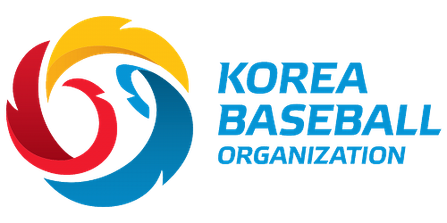

In [3]:
IPython.display.Image(filename = "../input/koreabaseball/kbo.png")

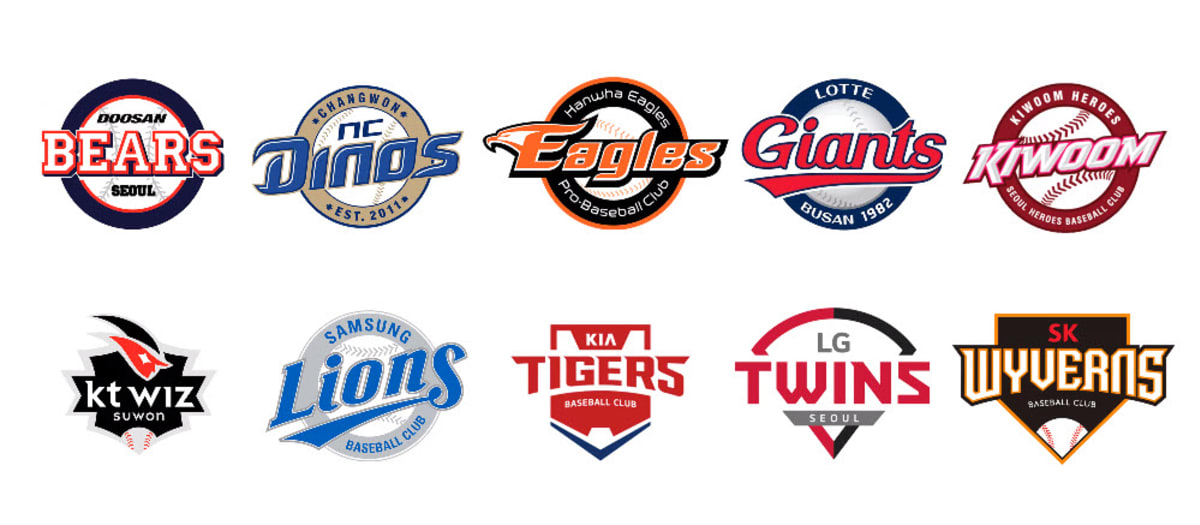

In [4]:
IPython.display.Image(filename = "../input/koreabaseball/koreabaseballlogos.png")

**The trophy for winning the KBO League World Series is a sword! It’s a real-life replica of the fabled “+9 Execution Sword” from the game Lineage, considered the most valuable item in the game.**

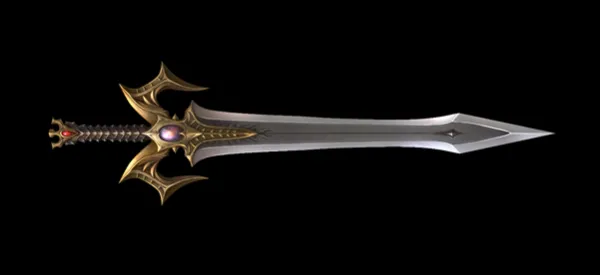

In [5]:
IPython.display.Image(filename = "../input/koreabaseball/kbosword.png")

# <span style="color:#821f1b">Columns in dataset</span> ⚾

***

- **`year`**
- **`teams`**
- **`average_batter_age`:** Average batter age
- **`runs_per_game`**: Runs scored per game
- **`games`**: Games played
- **`plate_appearances`**: Plate appearances
- **`at_bats`**: At bats
- **`hits`**: Hits
- **`runs`**: Runs
- **`doubles`**: Doubles
- **`triples`**: Triples
- **`homeruns`**: Home runs 
- **`RBI`**: Runs batted in
- **`stolen_bases`**: Bases stolen
- **`caught_stealing`**: Caught stealing
- **`bases_on_balls`**: Walks
- **`strikeouts`**
- **`batting_average`**: Batting average
- **`OBP`**: On base percentage
- **`SLG`**: Slugging percentage
- **`OPS`**: On base + slugging percentage
- **`total_bases`**: Total bases
- **`GDP`**: Double plays grounded into
- **`HBP`**: Times hit by pitch
- **`sacrifice_hits`**: Sacrifice hits
- **`sacrifice_flies`**: Sacrifice flies
- **`IBB`**: Intentional bases on balls

In [6]:
df.head()

,year,team,average_batter_age,runs_per_game,games,plate_appearances,at_bats,runs,hits,doubles,...,batting_average,OBP,SLG,OPS,total_bases,GDP,HBP,sacrifice_hits,sacrifice_flies,IBB
0,2021,SSG Landers,30.9,5.26,143,5698,4864,752,1268,203,...,0.261,0.354,0.421,0.775,2049,104,93,55,52,23.0
1,2021,Doosan Bears,29.0,5.13,143,5606,4867,733,1306,234,...,0.268,0.350,0.391,0.741,1901,137,86,45,52,12.0
2,2021,Lotte Giants,29.0,5.06,143,5689,4978,723,1384,263,...,0.278,0.356,0.399,0.755,1985,114,53,37,45,18.0
3,2021,Kiwoom Heroes,27.1,5.01,143,5610,4839,716,1250,243,...,0.258,0.347,0.376,0.722,1819,92,93,34,55,17.0
4,2021,KT Wiz,29.4,4.97,143,5581,4773,711,1263,217,...,0.265,0.356,0.380,0.736,1814,105,58,68,43,27.0


In [7]:
df.describe().style.background_gradient(cmap = "Reds")

,year,average_batter_age,runs_per_game,games,plate_appearances,at_bats,runs,hits,doubles,triples,homeruns,RBI,stolen_bases,caught_stealing,bases_on_balls,strikeouts,batting_average,OBP,SLG,OPS,total_bases,GDP,HBP,sacrifice_hits,sacrifice_flies,IBB
count,323.000000,323.000000,323.000000,323.000000,323.000000,323.000000,323.000000,323.000000,323.000000,323.000000,323.000000,323.000000,184.000000,184.000000,323.000000,323.000000,323.000000,323.000000,323.000000,323.000000,323.000000,323.000000,323.000000,323.000000,323.000000,184.000000
mean,2002.944272,27.785759,4.611610,128.142415,4919.773994,4293.430341,595.095975,1146.535604,197.798762,21.139319,106.582043,558.517028,105.489130,48.646739,447.910217,759.287926,0.266207,0.341700,0.395248,0.736882,1706.359133,97.151703,66.027864,75.037152,37.368421,17.788043
std,11.501957,1.335393,0.735030,12.996350,585.491296,508.741014,132.387325,179.164714,39.628473,8.154702,41.742950,128.400681,31.816068,12.270636,80.386728,207.925917,0.015558,0.017005,0.038147,0.052787,318.395835,18.809569,20.232864,25.553838,10.760400,6.200094
min,1982.000000,24.300000,2.710000,80.000000,2953.000000,2628.000000,302.000000,637.000000,110.000000,3.000000,29.000000,272.000000,47.000000,20.000000,221.000000,254.000000,0.219000,0.293000,0.301000,0.595000,914.000000,36.000000,24.000000,21.000000,11.000000,5.000000
25%,1993.000000,26.800000,4.005000,126.000000,4658.000000,4074.500000,495.500000,1028.000000,170.500000,15.000000,76.500000,462.000000,82.000000,41.000000,391.500000,622.500000,0.255000,0.329000,0.366500,0.698000,1490.000000,85.000000,51.500000,56.000000,30.000000,14.000000
50%,2003.000000,27.900000,4.590000,128.000000,4963.000000,4317.000000,590.000000,1143.000000,197.000000,20.000000,101.000000,554.000000,102.500000,47.500000,454.000000,776.000000,0.267000,0.342000,0.391000,0.733000,1673.000000,96.000000,65.000000,74.000000,37.000000,17.000000
75%,2013.000000,28.900000,5.155000,133.000000,5267.500000,4569.000000,693.500000,1264.000000,222.000000,26.000000,134.000000,652.500000,125.500000,57.000000,503.500000,911.500000,0.276500,0.355000,0.421500,0.774500,1928.000000,111.000000,80.000000,91.000000,44.000000,21.250000
max,2021.000000,30.900000,6.570000,144.000000,5870.000000,5176.000000,944.000000,1601.000000,304.000000,62.000000,234.000000,898.000000,204.000000,83.000000,639.000000,1278.000000,0.309000,0.382000,0.509000,0.891000,2518.000000,148.000000,130.000000,153.000000,83.000000,39.000000


In [8]:
df.shape

(323, 27)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 323 entries, 0 to 322
Data columns (total 27 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   year                323 non-null    int64  
 1   team                323 non-null    object 
 2   average_batter_age  323 non-null    float64
 3   runs_per_game       323 non-null    float64
 4   games               323 non-null    int64  
 5   plate_appearances   323 non-null    int64  
 6   at_bats             323 non-null    int64  
 7   runs                323 non-null    int64  
 8   hits                323 non-null    int64  
 9   doubles             323 non-null    int64  
 10  triples             323 non-null    int64  
 11  homeruns            323 non-null    int64  
 12  RBI                 323 non-null    int64  
 13  stolen_bases        184 non-null    float64
 14  caught_stealing     184 non-null    float64
 15  bases_on_balls      323 non-null    int64  
 16  strikeou

In [10]:
print(df.team.unique())

['SSG Landers' 'Doosan Bears' 'Lotte Giants' 'Kiwoom Heroes' 'KT Wiz'
 'Samsung Lions' 'NC Dinos' 'LG Twins' 'Hanwha Eagles' 'Kia Tigers'
 'SK Wyverns' 'Nexen Heroes' 'Woori Heroes' 'Hyundai Unicorns'
 'Haitai Tigers' 'Ssangbangwool Raiders' 'OB Bears' 'Pacific Dolphins'
 'Binggre Eagles' 'MBC Blue Dragons' 'Chungbo Pintos' 'Sammi Superstars']


# <span style="color:#821f1b">Total Number of Years Organizations Have Played in KBO</span>

<AxesSubplot:xlabel='count', ylabel='team'>

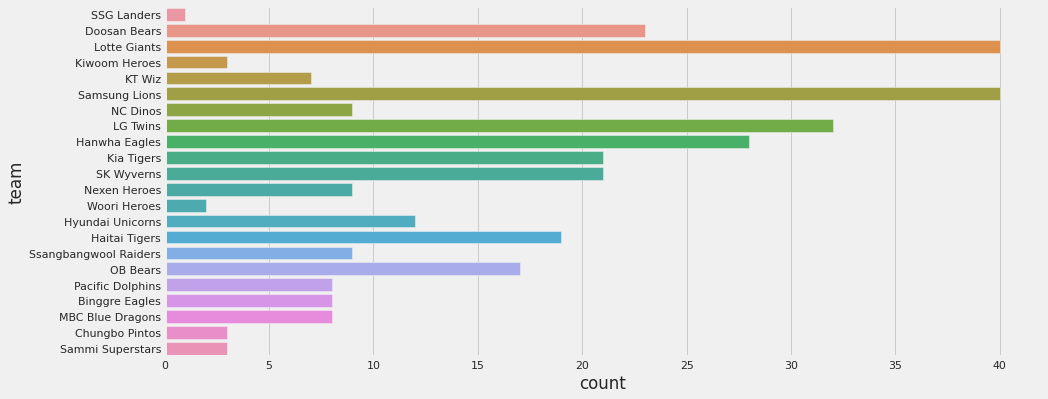

In [11]:
sns.countplot(data = df, y = "team")

# <span style="color:#821f1b">Games Played</span>

In [12]:
fig = px.bar(df, x = "year", y = "games", color = "games",
             color_continuous_scale = "algae_r",
             title = "Total Number of Games Played in KBO by Year ⚾")

fig.update_layout(template = "plotly_dark", font = dict(family = "PT Sans", size = 20, color = "#FFFFFF"))

fig.show()

# <span style="color:#821f1b">Average Batter Age by Year</span>

In [13]:
fig = px.scatter(df, x = "year", y = "average_batter_age", color = "average_batter_age",
                 color_continuous_scale = ["#000000", "#E27900", "#E27900"],
                 hover_name = "average_batter_age", hover_data = ["team"],
                 title = "Average Batter Age by Year ⚾ 🇰🇷")

fig.update_traces(marker = dict(size = 4))
fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

fig.show()

In [14]:
fig = px.bar(df, x = "year", y = "average_batter_age", color = "average_batter_age",
                 color_continuous_scale = "Turbo",
                 hover_name = "average_batter_age", hover_data = ["team"],
                 title = "Average Batter Age by Year ⚾ 🇰🇷")

fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

fig.show()

In [15]:
for teams in sorted(['Doosan Bears', 'Lotte Giants', 'Kiwoom Heroes', 'KT Wiz', 'Samsung Lions', 'NC Dinos', 
              'LG Twins', 'Hanwha Eagles', 'Kia Tigers', 'SK Wyverns', 'Nexen Heroes', 'Hyundai Unicorns',
              'Haitai Tigers', 'Ssangbangwool Raiders', 'OB Bears', 'Pacific Dolphins','Binggre Eagles', 
              'MBC Blue Dragons']):
    
    df0 = df[df["team"] == teams]
    
    fig = px.line(df0, x = "year", y = "average_batter_age", markers = True,
                  hover_name = "average_batter_age", title = f"{teams} Average Batter Age by Year ⚾ 🇰🇷")
    
    fig.update_traces(line_color = "#E27900")
    
    fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

    fig.show()

# <span style="color:#821f1b">Runs Scored Per Game by Year</span>
***

📌 **`Run` (R)** https://www.mlb.com/glossary/standard-stats/run

- A player is awarded a run if he crosses the plate to score his team a run. When tallying runs scored, the way in which a player reached base is not considered. If a player reaches base by an error or a fielder's choice, as long as he comes around to score, he is still credited with a run.

In [16]:
fig = px.scatter(df, x = "year", y = "runs_per_game", color = "runs_per_game",
                 color_continuous_scale = ["#000000", "#0007CD"],
                 hover_name = "runs_per_game", hover_data = ["team"],
                 title = "Runs Per Game by Year ⚾ 🇰🇷")

fig.update_traces(marker = dict(size = 4, ))#line = dict(width = 0.5, color = "#000000")))
fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

fig.show()

In [17]:
fig = px.bar(df, x = "year", y = "runs_per_game", color = "runs_per_game",
                 color_continuous_scale = "Turbo",
                 hover_name = "runs_per_game", hover_data = ["team"],
                 title = "Runs Per Game by Year ⚾ 🇰🇷")

fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

fig.show()

In [18]:
for teams in sorted(['Doosan Bears', 'Lotte Giants', 'Kiwoom Heroes', 'KT Wiz', 'Samsung Lions', 'NC Dinos', 
              'LG Twins', 'Hanwha Eagles', 'Kia Tigers', 'SK Wyverns', 'Nexen Heroes', 'Hyundai Unicorns',
              'Haitai Tigers', 'Ssangbangwool Raiders', 'OB Bears', 'Pacific Dolphins','Binggre Eagles', 
              'MBC Blue Dragons']):
    
    df0 = df[df["team"] == teams]
    
    fig = px.line(df0, x = "year", y = "runs_per_game", markers = True,
                  hover_name = "runs_per_game", title = f"{teams} Runs Per Game by Year ⚾ 🇰🇷")
    
    fig.update_traces(line_color = "#0007CD")
    
    fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

    fig.show()

# <span style="color:#821f1b">Average Doubles, Triples, Home Runs and RBIs Per Game by Year</span>
***

📌 **`Double` (2B)** https://www.mlb.com/glossary/standard-stats/double

- A batter is credited with a double when he hits the ball into play and reaches second base without the help of an intervening error or attempt to put out another baserunner.

***

📌 **`Triple` (3B)** https://www.mlb.com/glossary/standard-stats/triple

- Often called "the most exciting play in baseball," a triple occurs when a batter hits the ball into play and reaches third base without the help of an intervening error or attempt to put out another baserunner.

***

📌 **`Home Runs` (HR)** https://www.mlb.com/glossary/standard-stats/home-run

- A home run occurs when a batter hits a fair ball and scores on the play without being put out or without the benefit of an error.

***

📌 **Runs Batted In (`RBI`)** https://www.mlb.com/glossary/standard-stats/runs-batted-in

- A batter is credited with an RBI in most cases where the result of his plate appearance is a run being scored. There are a few exceptions, however. A player does not receive an RBI when the run scores as a result of an error or ground into double play.

In [19]:
fig = px.scatter(df, x = "year", y = "doubles", color = "doubles",
                 color_continuous_scale = ["#000000", "#0007CD"],
                 hover_name = "doubles", hover_data = ["team"],
                 title = "Total Doubles by Year ⚾ 🇰🇷")

fig.update_traces(marker = dict(size = 4, ))
fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

fig.show()

In [20]:
fig = px.bar(df, x = "year", y = "doubles", color = "doubles",
                 color_continuous_scale = "Turbo",
                 hover_name = "doubles", hover_data = ["team"],
                 title = "Total Doubles by Year ⚾ 🇰🇷")

fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

fig.show()

In [21]:
fig = px.scatter(df, x = "year", y = "triples", color = "triples",
                 color_continuous_scale = ["#000000", "#008000"],
                 hover_name = "triples", hover_data = ["team"],
                 title = "Total Triples by Year ⚾ 🇰🇷")

fig.update_traces(marker = dict(size = 5))
fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

fig.show()

In [22]:
fig = px.bar(df, x = "year", y = "triples", color = "triples",
                 color_continuous_scale = "Turbo",
                 hover_name = "triples", hover_data = ["team"],
                 title = "Total Triples by Year ⚾ 🇰🇷")

fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

fig.show()

In [23]:
fig = px.scatter(df, x = "year", y = "homeruns", color = "homeruns",
                 color_continuous_scale = ["#000000", "#F51B1B"],
                 hover_name = "homeruns", hover_data = ["team"],
                 title = "Total Home Runs by Year ⚾ 🇰🇷")

fig.update_traces(marker = dict(size = 4))
fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

fig.show()

In [24]:
fig = px.bar(df, x = "year", y = "homeruns", color = "homeruns",
                 color_continuous_scale = "Turbo",
                 hover_name = "homeruns", hover_data = ["team"],
                 title = "Total Home Runs by Year ⚾ 🇰🇷")

fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

fig.show()

In [25]:
fig = px.scatter(df, x = "year", y = "RBI", color = "RBI",
                 color_continuous_scale = ["#000000", "#00F7FF"],
                 hover_name = "RBI", hover_data = ["team"],
                 title = "Total RBIs by Year ⚾ 🇰🇷")

fig.update_traces(marker = dict(size = 4))
fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

fig.show()

In [26]:
fig = px.bar(df, x = "year", y = "RBI", color = "RBI",
                 color_continuous_scale = "Turbo",
                 hover_name = "RBI", hover_data = ["team"],
                 title = "Total RBIs by Year ⚾ 🇰🇷")

fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

fig.show()

In [27]:
df["2B"] = df.doubles/df.games
df["3B"] = df.triples/df.games
df["HR"] = df.homeruns/df.games
df["RBI"] = df.RBI/df.games

for teams in sorted(['Doosan Bears', 'Lotte Giants', 'Kiwoom Heroes', 'KT Wiz', 'Samsung Lions', 'NC Dinos', 
              'LG Twins', 'Hanwha Eagles', 'Kia Tigers', 'SK Wyverns', 'Nexen Heroes', 'Hyundai Unicorns',
              'Haitai Tigers', 'Ssangbangwool Raiders', 'OB Bears', 'Pacific Dolphins','Binggre Eagles', 
              'MBC Blue Dragons']):
    
    df0 = df[df["team"] == teams]
    
    fig = px.line(df0, x = "year", y = ["RBI", "2B", "HR", "3B"], markers = True,
                  hover_name = "value", title = f"{teams} Average 2B, 3B, HR and RBI Per Game by Year ⚾ 🇰🇷")
    
    fig["data"][0]["line"]["color"] = "#000000"
    fig["data"][1]["line"]["color"] = "#000480"
    fig["data"][2]["line"]["color"] = "#F51B1B"
    fig["data"][3]["line"]["color"] = "#008000"
    
    fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

    fig.show()

# <span style="color:#821f1b">Stolen Bases & Caught Stealing</span>
***

📌 **`Stolen Bases` (SB)** https://www.mlb.com/glossary/standard-stats/stolen-base

- A stolen base occurs when a baserunner advances by taking a base to which he isn't entitled. This generally occurs when a pitcher is throwing a pitch, but it can also occur while the pitcher still has the ball or is attempting a pickoff, or as the catcher is throwing the ball back to the pitcher.

***

📌 **`Caught Stealing` (CS)** https://www.mlb.com/glossary/standard-stats/caught-stealing

- A caught stealing occurs when a runner attempts to steal but is tagged out before reaching second base, third base or home plate. This typically happens after a pitch, when a catcher throws the ball to the fielder at the base before the runner reaches it. But it can also happen before a pitch, typically when a pitcher throws the ball to first base for a pickoff attempt but the batter has already left for second.

In [28]:
for teams in sorted(['Doosan Bears', 'Lotte Giants', 'Kiwoom Heroes', 'KT Wiz', 'Samsung Lions', 'NC Dinos', 
              'LG Twins', 'Hanwha Eagles', 'Kia Tigers', 'SK Wyverns', 'Nexen Heroes', 'Hyundai Unicorns']):
    
    df0 = df[df["team"] == teams]
    
    fig = px.line(df0, x = "year", y = ["stolen_bases", "caught_stealing"], markers = True,
                  hover_name = "value", title = f"{teams} Stolen Bases & Caught Stealing by Year ⚾ 🇰🇷")
    
    fig["data"][0]["line"]["color"] = "#000480"
    fig["data"][1]["line"]["color"] = "#F51B1B"
    
    if teams == "NC Dinos":
        fig.add_annotation( # add a text callout
        text = "KBO Record 204 Stolen Bases", x = 2015, y = 204, yanchor = "bottom")
    
    fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

    fig.show()

# <span style="color:#821f1b">Batting Average, Strikeout Percentage, Bases on Balls Percentage</span>
***

📌 **`Batting Average` (BA)** https://www.mlb.com/glossary/standard-stats/batting-average

- One of the oldest and most universal tools to measure a hitter's success at the plate, batting average is determined by dividing a player's hits by his total at-bats for a number between zero (shown as .000) and one (1.000). In recent years, the league-wide batting average has typically hovered around .250.

***

📌 **`Strikeouts` (SO, K)** https://www.mlb.com/glossary/standard-stats/strikeout

- A strikeout occurs when a pitcher throws any combination of three swinging or looking strikes to a hitter. (A foul ball counts as a strike, but it cannot be the third and final strike of the at-bat. A foul tip, which is caught by the catcher, is considered a third strike.)

***

📌 **`Walk` (BB)** https://www.mlb.com/glossary/standard-stats/walk

- A walk (or base on balls) occurs when a pitcher throws four pitches out of the strike zone, none of which are swung at by the hitter. After refraining from swinging at four pitches out of the zone, the batter is awarded first base. In the scorebook, a walk is denoted by the letters BB.

In [29]:
df["walk_percentage"] = df.bases_on_balls/df.plate_appearances
df["strikeout_percentage"] = df.strikeouts/df.plate_appearances

for teams in sorted(['Doosan Bears', 'Lotte Giants', 'Kiwoom Heroes', 'KT Wiz', 'Samsung Lions', 'NC Dinos', 
              'LG Twins', 'Hanwha Eagles', 'Kia Tigers', 'SK Wyverns', 'Nexen Heroes', 'Hyundai Unicorns',
              'Haitai Tigers', 'Ssangbangwool Raiders', 'OB Bears', 'Pacific Dolphins','Binggre Eagles', 
              'MBC Blue Dragons']):
    
    df0 = df[df["team"] == teams]
    
    fig = px.line(df0, x = "year", y = ["batting_average", "strikeout_percentage", "walk_percentage"], 
                  markers = True, hover_name = "value",
                  title = f"{teams} Batting Average, Strikeouts and Walks by Year ⚾ 🇰🇷")
    
    fig["data"][0]["line"]["color"] = "#000000"
    fig["data"][1]["line"]["color"] = "#F51B1B"
    fig["data"][2]["line"]["color"] = "#000480"
    
    fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

    fig.show()

# <span style="color:#821f1b">OBP, SLG, OPS</span>
***

📌 **On-base Percentage (`OBP`)** https://www.mlb.com/glossary/standard-stats/on-base-percentage

- OBP refers to how frequently a batter reaches base per plate appearance. Times on base include hits, walks and hit-by-pitches, but do not include errors, times reached on a fielder's choice or a dropped third strike.

***

📌 **Slugging Percentage (`SLG`)** https://www.mlb.com/glossary/standard-stats/slugging-percentage

- Slugging percentage represents the total number of bases a player records per at-bat. Unlike on-base percentage, slugging percentage deals only with hits and does not include walks and hit-by-pitches in its equation.

***

📌 **On-base Plus Slugging (`OPS`)** https://www.mlb.com/glossary/standard-stats/on-base-plus-slugging

- OPS adds on-base percentage and slugging percentage to get one number that unites the two. It's meant to combine how well a hitter can reach base, with how well he can hit for average and for power.

In [30]:
for teams in sorted(['Doosan Bears', 'Lotte Giants', 'Kiwoom Heroes', 'KT Wiz', 'Samsung Lions', 'NC Dinos', 
              'LG Twins', 'Hanwha Eagles', 'Kia Tigers', 'SK Wyverns', 'Nexen Heroes', 'Hyundai Unicorns',
              'Haitai Tigers', 'Ssangbangwool Raiders', 'OB Bears', 'Pacific Dolphins','Binggre Eagles', 
              'MBC Blue Dragons']):
    
    df0 = df[df["team"] == teams]
    
    fig = px.line(df0, x = "year", y = ["OPS", "SLG", "OBP"], 
                  markers = True, hover_name = "value",
                  title = f"{teams} OBP, SLG, OPS by Year ⚾ 🇰🇷")
    
    fig["data"][0]["line"]["color"] = "#8C00A8"
    fig["data"][1]["line"]["color"] = "#F51B1B"
    fig["data"][2]["line"]["color"] = "#000480"
    
    fig.update_layout(template = "ggplot2", font = dict(family = "PT Sans", size = 20, color = "#821f1b"))

    fig.show()

**Thank you for viewing this notebook. Please feel free to provide any feedback on this notebook or the dataset associated with it!**